# 01 Logistic Regression
คิดคะแนน `z = w·x + b` แล้วแปลงเป็นความน่าจะเป็นด้วย sigmoid
เทรนด้วย gradient descent + L2 ให้น้ำหนักคนผิดนัดมากขึ้นเพราะมีน้อย หยุดเมื่อ validation loss ไม่ลด

โค้ด: `Model/Classification/Logisticregression.py`  
ผลลัพธ์: `Results/Classification/01_Logistic_Regression/`

## 1. เตรียมข้อมูล

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
import pandas as pd
from project import Outputs, classification_data, imbalance_weight
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from Logisticregression import LogisticRegressionScratch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

out = Outputs("Classification", "01_Logistic_Regression")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. เทรนโมเดล

In [2]:
model = LogisticRegressionScratch(learning_rate=0.5, n_iterations=500, reg_lambda=1.0)
check_settings("Logistic Regression", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

sc = StandardScaler().fit(d.X_tr)
sk = LogisticRegression(max_iter=5000, tol=1e-10).fit(
    sc.transform(d.X_tr), d.y_tr, sample_weight=imbalance_weight(d.y_tr)
)
check = sklearn_check(
    "Logistic Regression vs sklearn LogisticRegression",
    np.abs(model.coef_ - sk.coef_[0]).max(),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, sk.predict_proba(sc.transform(d.X_te))[:, 1]),
    "max |dcoef|",
)

settings match Common/model_zoo.py (9 values checked)


## 3. ผลลัพธ์

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2207        0.5000
log loss                            0.4590           NaN
accuracy                            0.4483        0.8132
precision                           0.2058        0.3468
recall / sensitivity                0.8623        0.1967
specificity                         0.3700           NaN
F1                                  0.3323        0.2510
ROC-AUC                             0.7067           NaN
PR-AUC                              0.2966           NaN
defaulters missed (FN)             42.0000           NaN

catches 86.2% of the 305 test defaulters (42 missed), flags 66.7% of applicants


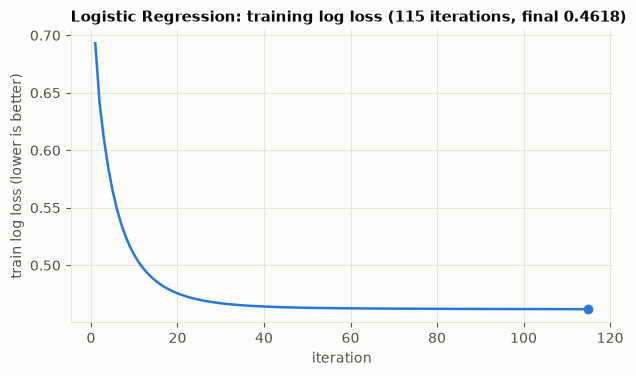

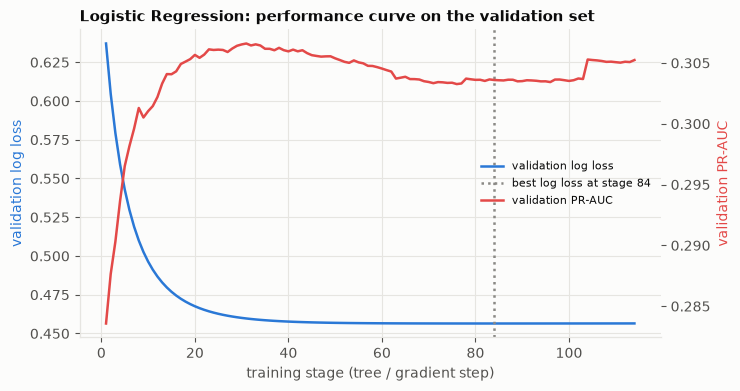

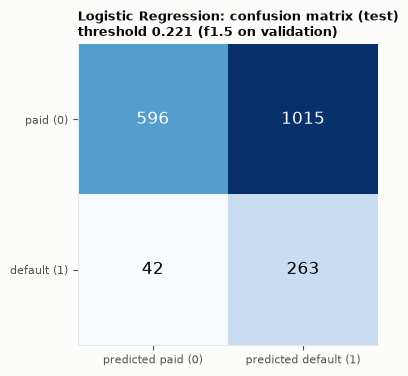

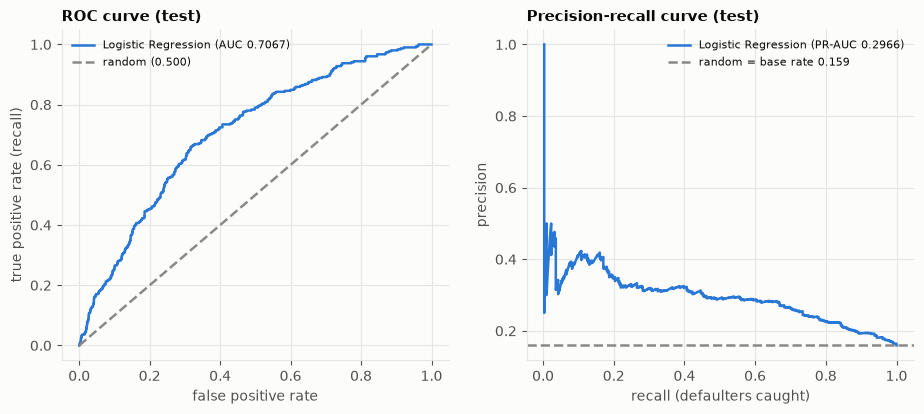

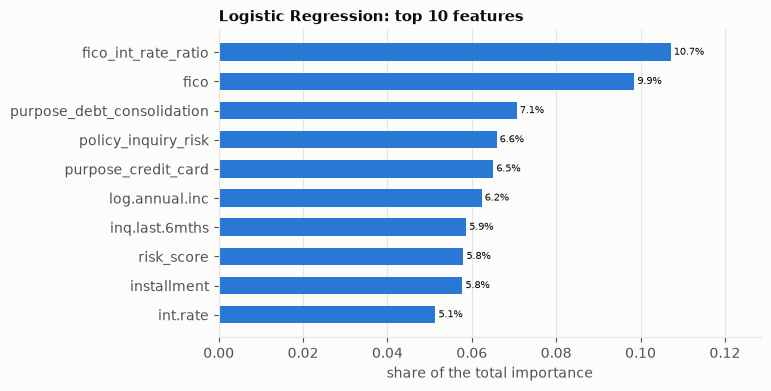


scratch vs library:
  Logistic Regression vs sklearn LogisticRegression
    AUC scratch 0.7067 | AUC library 0.7044 | max |dcoef| = 0.469

saved + reloaded Results/Classification/01_Logistic_Regression/model.joblib (identical predictions: True)

strongest coefficients (per 1 SD):
                            coef_per_1SD  odds_ratio  importance
feature                                                         
fico_int_rate_ratio            -0.233317    0.791903    0.107170
fico                           -0.214508    0.806938    0.098531
purpose_debt_consolidation     -0.153808    0.857436    0.070649
policy_inquiry_risk             0.143430    1.154226    0.065882
purpose_credit_card            -0.141698    0.867883    0.065087
log.annual.inc                 -0.135739    0.873070    0.062349
inq.last.6mths                  0.127695    1.136206    0.058654
risk_score                      0.126309    1.134633    0.058018


In [3]:
row = report_classifier(out, "Logistic Regression", model, d, check)

coefs = pd.DataFrame(model.coefficient_table()).set_index("feature")
coefs.to_csv(out.table("coefficients.csv"))
print("\nstrongest coefficients (per 1 SD):")
print(coefs.reindex(coefs["coef_per_1SD"].abs().sort_values(ascending=False).index).head(8).to_string())